---
# 0. Setup

In [50]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, TargetEncoder
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# import pyspark as spark

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:,.2f}'.format)
sns.set_theme(style='whitegrid')

# Notebooks live in EDA/, data lives in <repo root>/data/ (git-ignored -- never commit it).
DATA_DIR = Path('..') / 'data'

PAX_PATH = DATA_DIR / 'AA_PAX_FORECASTING.csv'

AIRPRT_PATH = DATA_DIR / 'AA_AIRPORT_INFO.csv'

---
# 1.  Load



In [2]:
pax_raw = pd.read_csv(
    PAX_PATH,
    index_col=0,   # nameless exported row-number column -> index, not a feature
    dtype={'ORG_AIRPRT': 'category', 'DES_AIRPRT': 'category'},
)
pax = pax_raw.copy()
print(pax.shape)
print(f"{pax.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
pax.drop(columns=['SF_LOAD_TMS'], inplace=True)
pax.head()

airprt_raw = pd.read_csv(
    AIRPRT_PATH,
    index_col=0,
    dtype={'ORG_AIRPRT': 'category', 'DES_AIRPRT': 'category'},
)
airprt = airprt_raw.copy()
print(airprt.shape)
print(f"{airprt.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
airprt.drop(columns=['SF_LOAD_TMS'], inplace=True)


(1533522, 7)
178 MB
(4565, 17)
2 MB


---
# 2. Previews


In [3]:
pax.head()

,DEP_MONTH,DEP_YEAR,ORG_AIRPRT,DES_AIRPRT,OD_PAX,OD_REV_USD
0,12,2023,SAN,PVR,"3,609.91","562,691.27"
1,12,2019,SAN,PVR,"3,271.89","533,964.07"
2,8,2022,SAN,PVR,"1,435.84","167,189.61"
3,2,2021,SAN,PVR,546.57,"80,287.17"
4,5,2021,SAN,PVR,"1,741.58","273,545.15"


In [4]:
airprt.head()

,AIRPRT_CD,AIRPRT_NM,CITY_METRO_IATA_CD,STATE_PROVNC_CD,CNTRY_CD,WRLD_AREA_DOT_CD,LAT_DEGREE_QTY,LAT_MINUTE_QTY,LAT_SECOND_QTY,LAT_HEMSPHR_CD,LNGTD_DEGREE_QTY,LNGTD_MINUTE_QTY,LNGTD_SECOND_QTY,LNGTD_HEMSPHR_CD,LNGST_RUNWAY_FT_QTY,ELEVATN_FT_QTY
0,OAH,Shindand Air Base,OAH,NaN,AF,701,33,23,32,N,62,15,40,E,7900,3780
1,REX,Lucio Blanco Intl,REX,NaN,MX,148,26,0,30,N,98,13,41,W,6200,139
2,YQX,Gander Intl.,YQX,NL,CA,961,48,56,13,N,54,34,5,W,10200,496
3,MLW,Spriggs Payne,MLW,NaN,LR,537,6,17,19,N,10,45,32,W,6000,26
4,CIJ,Capitan Anibal Arab,CIJ,NaN,BO,312,11,2,16,S,68,47,0,W,8500,805


In [5]:
print(airprt.info())
print(airprt.describe(include='all'))
print(airprt.nunique())

<class 'pandas.core.frame.DataFrame'>
Index: 4565 entries, 0 to 4564
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   AIRPRT_CD            4565 non-null   object
 1   AIRPRT_NM            4565 non-null   object
 2   CITY_METRO_IATA_CD   4565 non-null   object
 3   STATE_PROVNC_CD      2182 non-null   object
 4   CNTRY_CD             4557 non-null   object
 5   WRLD_AREA_DOT_CD     4565 non-null   int64 
 6   LAT_DEGREE_QTY       4565 non-null   int64 
 7   LAT_MINUTE_QTY       4565 non-null   int64 
 8   LAT_SECOND_QTY       4565 non-null   int64 
 9   LAT_HEMSPHR_CD       4565 non-null   object
 10  LNGTD_DEGREE_QTY     4565 non-null   int64 
 11  LNGTD_MINUTE_QTY     4565 non-null   int64 
 12  LNGTD_SECOND_QTY     4565 non-null   int64 
 13  LNGTD_HEMSPHR_CD     4565 non-null   object
 14  LNGST_RUNWAY_FT_QTY  4565 non-null   int64 
 15  ELEVATN_FT_QTY       4565 non-null   int64 
dtypes: int64(9)

In [6]:
print(pax.info())
print(pax.describe(include='all'))
print(pax.nunique())


<class 'pandas.core.frame.DataFrame'>
Index: 1533522 entries, 0 to 1533521
Data columns (total 6 columns):
 #   Column      Non-Null Count    Dtype   
---  ------      --------------    -----   
 0   DEP_MONTH   1533522 non-null  int64   
 1   DEP_YEAR    1533522 non-null  int64   
 2   ORG_AIRPRT  1533522 non-null  category
 3   DES_AIRPRT  1533522 non-null  category
 4   OD_PAX      1533522 non-null  float64 
 5   OD_REV_USD  1533522 non-null  float64 
dtypes: category(2), float64(2), int64(2)
memory usage: 64.4 MB
None
          DEP_MONTH     DEP_YEAR ORG_AIRPRT DES_AIRPRT       OD_PAX  \
count  1,533,522.00 1,533,522.00    1533522    1533522 1,533,522.00   
unique          NaN          NaN        150        150          NaN   
top             NaN          NaN        ATL        BNA          NaN   
freq            NaN          NaN      13326      13467          NaN   
mean           6.31     2,022.34        NaN        NaN     2,765.16   
std            3.44         2.20        NaN   

## Pax
Very heavily skewed OD_PAX, OD_REV_USD. The rest are rather evenly distributed (airports). The month and year are just dates split into two. 

## Airprt
Contains a lot of metrics on an airport, including their location, runways length, elevation, name, etc. Most of it is just informational. 

---
# 3 Imputing Data

### 3.1 Missing values, duplicates, and the key

In [7]:

print(pax.duplicated().sum())
print(pax[pax['ORG_AIRPRT'] == pax['DES_AIRPRT']])
print(pax.isnull().value_counts())


0
Empty DataFrame
Columns: [DEP_MONTH, DEP_YEAR, ORG_AIRPRT, DES_AIRPRT, OD_PAX, OD_REV_USD]
Index: []
DEP_MONTH  DEP_YEAR  ORG_AIRPRT  DES_AIRPRT  OD_PAX  OD_REV_USD
False      False     False       False       False   False         1533522
Name: count, dtype: int64


In [14]:
# print(airprt.duplicated().sum())
airprt.isnull().value_counts()
print(airprt.CNTRY_CD.isnull().value_counts())
print(airprt.STATE_PROVNC_CD.isnull().value_counts())


CNTRY_CD
False    4557
True        8
Name: count, dtype: int64
STATE_PROVNC_CD
True     2383
False    2182
Name: count, dtype: int64


Let's fill in the NaN's with MISSING.

In [17]:
airprt.STATE_PROVNC_CD = airprt.STATE_PROVNC_CD.fillna("MISSING").replace("","MISSING")
airprt.CNTRY_CD = airprt.CNTRY_CD.fillna("MISSING").replace("","MISSING")
airprt.isnull().value_counts()


AIRPRT_CD  AIRPRT_NM  CITY_METRO_IATA_CD  STATE_PROVNC_CD  CNTRY_CD  WRLD_AREA_DOT_CD  LAT_DEGREE_QTY  LAT_MINUTE_QTY  LAT_SECOND_QTY  LAT_HEMSPHR_CD  LNGTD_DEGREE_QTY  LNGTD_MINUTE_QTY  LNGTD_SECOND_QTY  LNGTD_HEMSPHR_CD  LNGST_RUNWAY_FT_QTY  ELEVATN_FT_QTY
False      False      False               False            False     False             False           False           False           False           False             False             False             False             False                False             4565
Name: count, dtype: int64

### 3.2 Explore -- Pax

In [18]:

for col in pax.columns:
    
    print(col,pax[col].value_counts().sort_values(ascending=False))

DEP_MONTH DEP_MONTH
1     136230
3     136101
2     135768
7     134625
6     133153
4     132878
5     132560
12    119220
11    119028
10    118532
9     117832
8     117595
Name: count, dtype: int64
DEP_YEAR DEP_YEAR
2023    205324
2025    205313
2024    205267
2019    205267
2022    205062
2021    201882
2020    185753
2026    119654
Name: count, dtype: int64
ORG_AIRPRT ORG_AIRPRT
ATL    13326
SEA    13307
DEN    13303
PHX    13297
MSP    13290
       ...  
MDE     4695
LIS     4416
HKG     3875
SFB     1240
PIE     1158
Name: count, Length: 150, dtype: int64
DES_AIRPRT DES_AIRPRT
BNA    13467
PIT    13433
IND    13431
MEM    13375
ATL    13349
       ...  
PVG     3266
HKG     2983
SGN     1468
SFB     1244
PIE     1156
Name: count, Length: 150, dtype: int64
OD_PAX OD_PAX
1.00        114
1.96        104
3.48         99
2.00         96
2.08         96
           ... 
1,888.32      1
3,426.20      1
2,031.87      1
1,880.67      1
1,128.06      1
Name: count, Length: 511058, dtype: 

In [19]:

key = ["DEP_YEAR","DEP_MONTH"]
pax_num = pax.select_dtypes(include="number")
num_cols = pax_num.columns.drop(key, errors="ignore")
cat_cols = [c for c in pax.columns if c not in pax_num.columns and c != key]

out = pax.groupby( key).agg({
    **{c: "mean" for c in num_cols},
    **{c: "count" for c in cat_cols},   # first value in each group
})
# print(out)

print(out.describe())
print(pax_num.head())


        OD_PAX   OD_REV_USD  ORG_AIRPRT  DES_AIRPRT
count    91.00        91.00       91.00       91.00
mean  2,736.54   679,360.73   16,851.89   16,851.89
std     801.64   277,551.42      756.58      756.58
min     144.16    25,997.60   13,039.00   13,039.00
25%   2,615.16   521,052.01   17,061.50   17,061.50
50%   2,972.60   767,195.39   17,106.00   17,106.00
75%   3,286.79   872,459.27   17,110.00   17,110.00
max   3,662.64 1,076,465.32   17,118.00   17,118.00
   DEP_MONTH  DEP_YEAR   OD_PAX  OD_REV_USD
0         12      2023 3,609.91  562,691.27
1         12      2019 3,271.89  533,964.07
2          8      2022 1,435.84  167,189.61
3          2      2021   546.57   80,287.17
4          5      2021 1,741.58  273,545.15


Usually few thousands of passengers per month (Normally ~2000-3000+) with hundreds of thousands (normally 500k - 850k+) of revenue dollars. 

         DATE  DEP_MONTH  DEP_YEAR   OD_PAX   OD_REV_USD
0  2019-01-01       1.00  2,019.00 2,680.61   624,902.89
1  2019-02-01       2.00  2,019.00 2,554.39   572,035.57
2  2019-03-01       3.00  2,019.00 3,207.21   733,188.64
3  2019-04-01       4.00  2,019.00 3,106.06   722,320.98
4  2019-05-01       5.00  2,019.00 3,281.44   779,002.46
..        ...        ...       ...      ...          ...
86 2026-03-01       3.00  2,026.00 2,981.08   845,547.34
87 2026-04-01       4.00  2,026.00 3,152.90   978,993.09
88 2026-05-01       5.00  2,026.00 2,910.76   854,754.97
89 2026-06-01       6.00  2,026.00 2,912.40 1,076,465.32
90 2026-07-01       7.00  2,026.00 3,364.68 1,024,926.86

[91 rows x 5 columns]


<Axes: xlabel='DATE'>

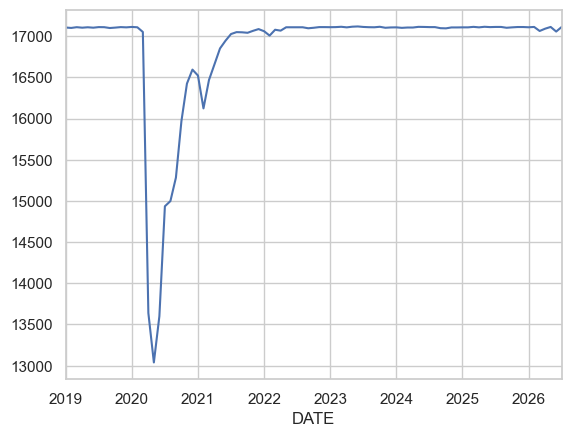

In [20]:

pax['DATE'] = pd.to_datetime(dict(year=pax['DEP_YEAR'], month=pax['DEP_MONTH'], day=1))
out = pax.groupby("DATE").mean(numeric_only=True).sort_index()
out.reset_index(inplace=True)
print(out)
pax.groupby('DATE').size().plot()



count   1,533,522.00
mean          384.73
std           331.84
min             0.00
25%           200.06
50%           276.54
75%           433.61
max        22,311.81
Name: AVG_FARE, dtype: float64


<Axes: ylabel='Frequency'>

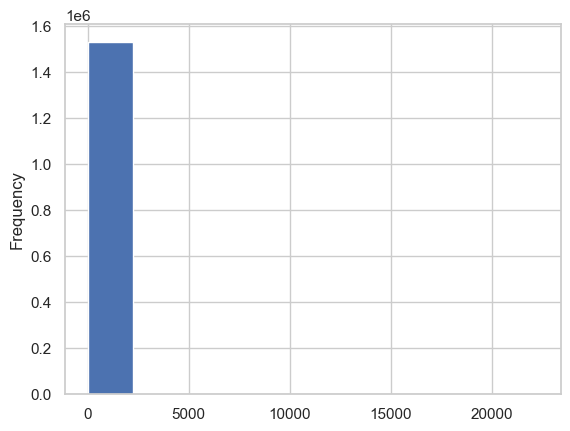

In [21]:
#Let's also add the average revenue
pax['AVG_FARE'] = pax['OD_REV_USD'] / pax['OD_PAX']
print(pax['AVG_FARE'].describe())
pax['AVG_FARE'].plot(kind='hist')

count   1,533,522.00
mean            5.72
std             0.65
min             0.00
25%             5.30
50%             5.63
75%             6.07
max            10.01
Name: AVG_FARE_LOG, dtype: float64


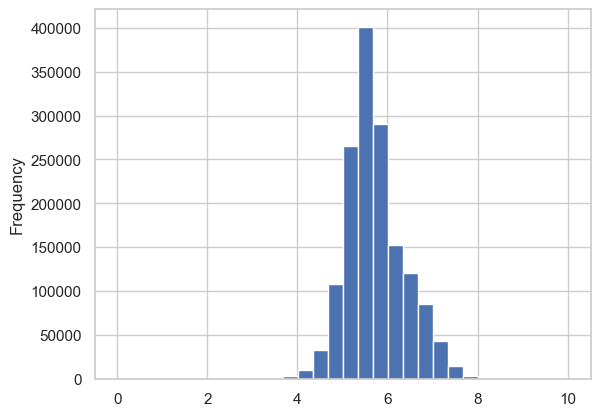

In [22]:
#Logging the average fare because it's so skewed
pax['AVG_FARE_LOG'] = np.log1p(pax.AVG_FARE)
pax.AVG_FARE_LOG.plot(kind='hist',bins =30)
print(pax.AVG_FARE_LOG.describe())


The log looks a lot better, so let's do that to the PAX and REV_USD too. 

In [23]:
pax['OD_REV_USD_LOG'] = np.log1p(pax.OD_REV_USD)
pax['OD_PAX_LOG'] = np.log1p(pax.OD_PAX)
print(pax.OD_REV_USD_LOG.describe())
print(pax.OD_PAX_LOG.describe())

count   1,533,522.00
mean           11.92
std             1.91
min             0.00
25%            10.75
50%            11.96
75%            13.23
max            18.61
Name: OD_REV_USD_LOG, dtype: float64
count   1,533,522.00
mean            6.22
std             2.02
min             0.12
25%             4.87
50%             6.22
75%             7.65
max            11.85
Name: OD_PAX_LOG, dtype: float64


<Axes: ylabel='Frequency'>

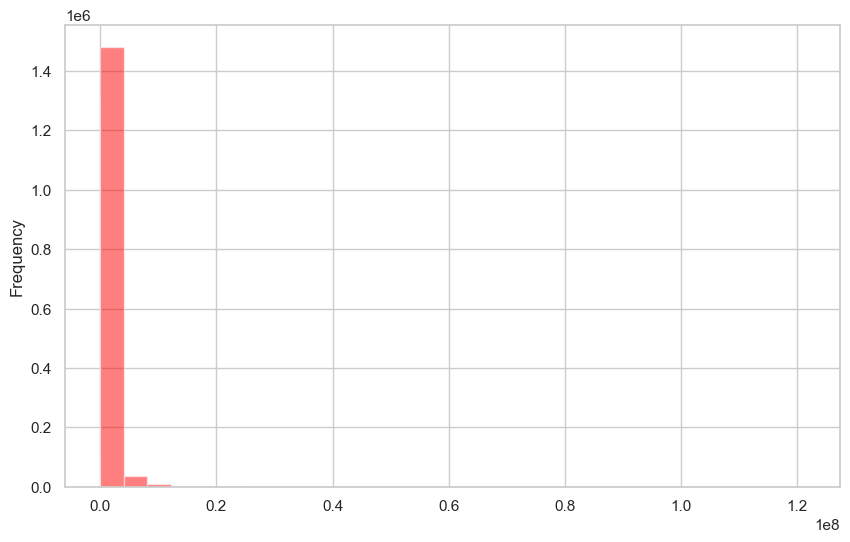

In [24]:
plt.figure(figsize = (10,6))
pax.OD_PAX.plot(kind='hist',alpha=0.5, color='blue',bins=30)
pax.OD_REV_USD.plot(kind='hist',alpha=0.5, color='red',bins=30)

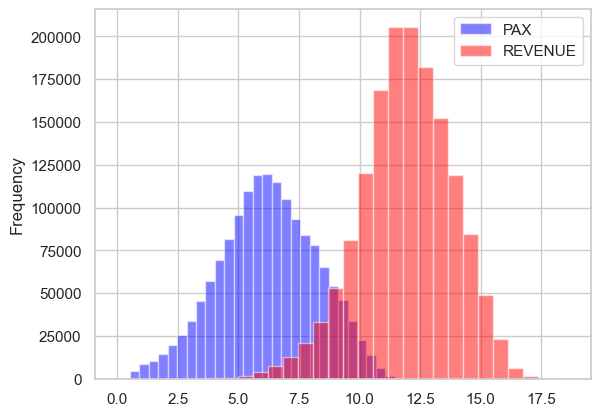

In [25]:

pax.OD_PAX_LOG.plot(kind='hist',alpha=0.5, color='blue',bins=30,label='PAX')
pax.OD_REV_USD_LOG.plot(kind='hist',alpha=0.5, color='red',bins=30,label='REVENUE')
plt.legend()
plt.show()
# pax.OD_PAX.plot(kind='hist',alpha=0.5, color='blue',bins=30,label='PAX')
# pax.OD_REV_USD.plot(kind='hist',alpha=0.5, color='red',bins=30,label='REVENUE')
# plt.xscale('log')
# plt.legend()
# plt.show()


<Axes: >

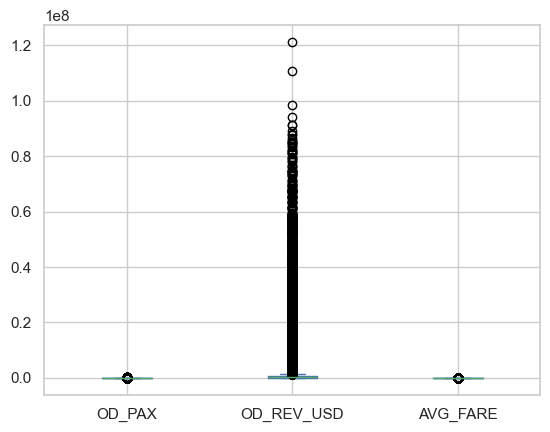

In [26]:
pax.plot(kind='box',column = ['OD_PAX','OD_REV_USD','AVG_FARE'])

<Axes: >

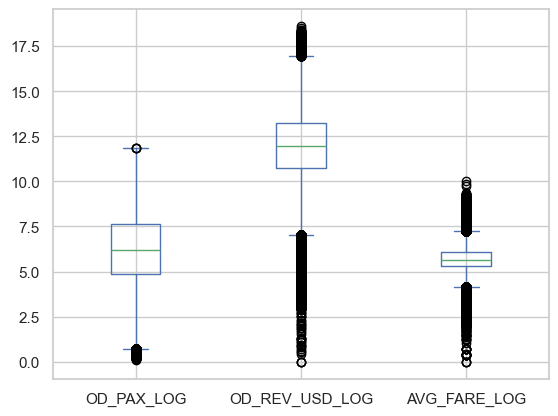

In [27]:
pax.plot(kind='box',column = ['OD_PAX_LOG','OD_REV_USD_LOG','AVG_FARE_LOG'])

A lot more normal. We'll use these for calculations.

<Figure size 1000x600 with 0 Axes>

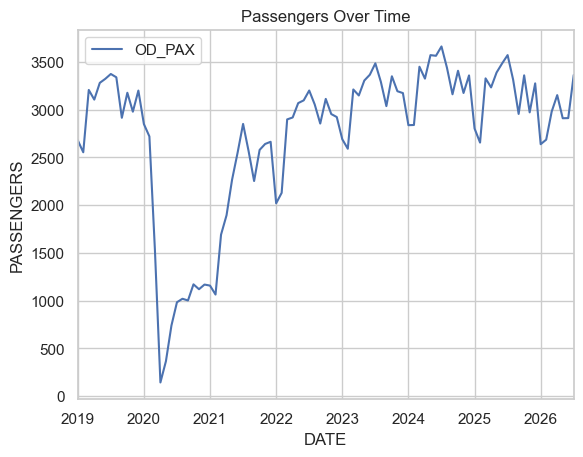

<Figure size 1000x600 with 0 Axes>

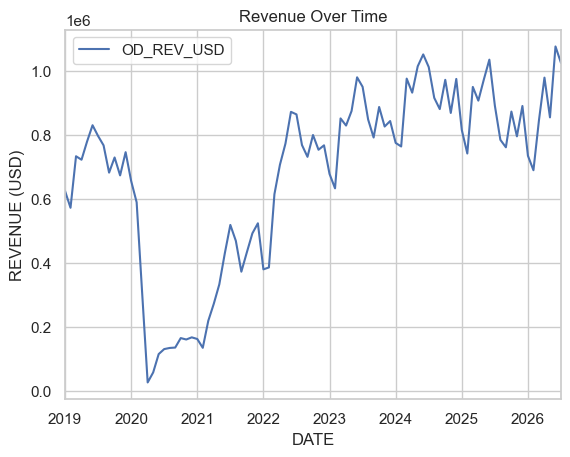

In [28]:
plt.figure(figsize=(10,6))
out.plot(x='DATE',y='OD_PAX', kind='line')
plt.xlabel("DATE")
plt.ylabel("PASSENGERS")
plt.title("Passengers Over Time")
plt.show()
plt.figure(figsize=(10,6))
out.plot(x='DATE',y='OD_REV_USD',kind='line')
plt.xlabel("DATE")
plt.ylabel("REVENUE (USD)")
plt.title("Revenue Over Time")
plt.show()

In [29]:
# TODO: panel completeness. For each route (ORG, DES), how many of the possible months does it have?
#   route_months = pax.groupby(['ORG_AIRPRT', 'DES_AIRPRT'], observed=True)['DATE'].nunique()
#   route_months.describe(); route_months.hist(bins=50)
# Routes with gaps matter: a missing month could mean "0 passengers" or "no data". Which is it here?
# (observed=True stops pandas building every possible category pair -- 150 x 150 combos.)

pax['ROUTE'] = pax['ORG_AIRPRT'].astype(str) + '-' + pax['DES_AIRPRT'].astype(str)
print(pax.ROUTE.value_counts())
print(pax.nunique())
# print(pax.ROUTE.nunique())



ROUTE
NRT-DEN    91
NRT-DCA    91
SAN-PWM    91
SAN-RDU    91
SAN-RIC    91
           ..
SYR-TLV    81
AUA-RNO    81
AUA-ABQ    81
LIH-SYR    81
NAS-TUS    81
Name: count, Length: 17119, dtype: int64
DEP_MONTH              12
DEP_YEAR                8
ORG_AIRPRT            150
DES_AIRPRT            150
OD_PAX             511058
OD_REV_USD        1506798
DATE                   91
AVG_FARE          1533372
AVG_FARE_LOG      1533310
OD_REV_USD_LOG    1506798
OD_PAX_LOG         511058
ROUTE               17119
dtype: int64


In [30]:
pax.groupby('ROUTE')[['OD_PAX','OD_REV_USD','OD_PAX_LOG','OD_REV_USD_LOG']].mean().sort_values(by=['OD_PAX','OD_REV_USD'],ascending=False)



,OD_PAX,OD_REV_USD,OD_PAX_LOG,OD_REV_USD_LOG
ROUTE,,,,
JFK-LAX,"92,238.59","42,617,469.98",11.31,17.38
LAX-JFK,"92,085.86","43,187,653.98",11.30,17.38
LGA-ORD,"71,440.84","12,918,354.81",10.97,16.08
ORD-LGA,"71,233.79","12,894,932.94",10.96,16.07
SFO-LAX,"70,314.80","7,696,599.50",11.01,15.67
...,...,...,...,...
ALB-SAL,10.73,"4,469.43",2.14,7.71
ALB-PVD,9.00,"2,964.73",2.06,7.64
SAL-ALB,8.77,"3,631.72",2.07,7.69


In [31]:
date = pax.pop('DATE')
route = pax.pop('ROUTE')
pax.insert(2,'DATE',date)
pax.insert(5,'ROUTE',route)
# pax.sort_values(by='DATE',inplace=True)
# pax.sort_index(inplace=True)
pax.head()

,DEP_MONTH,DEP_YEAR,DATE,ORG_AIRPRT,DES_AIRPRT,ROUTE,OD_PAX,OD_REV_USD,AVG_FARE,AVG_FARE_LOG,OD_REV_USD_LOG,OD_PAX_LOG
0,12,2023,2023-12-01,SAN,PVR,SAN-PVR,"3,609.91","562,691.27",155.87,5.06,13.24,8.19
1,12,2019,2019-12-01,SAN,PVR,SAN-PVR,"3,271.89","533,964.07",163.20,5.10,13.19,8.09
2,8,2022,2022-08-01,SAN,PVR,SAN-PVR,"1,435.84","167,189.61",116.44,4.77,12.03,7.27
3,2,2021,2021-02-01,SAN,PVR,SAN-PVR,546.57,"80,287.17",146.89,5.00,11.29,6.31
4,5,2021,2021-05-01,SAN,PVR,SAN-PVR,"1,741.58","273,545.15",157.07,5.06,12.52,7.46


## 3.3 Explore and Modify -- Airprt

In [32]:
airprt.head()

,AIRPRT_CD,AIRPRT_NM,CITY_METRO_IATA_CD,STATE_PROVNC_CD,CNTRY_CD,WRLD_AREA_DOT_CD,LAT_DEGREE_QTY,LAT_MINUTE_QTY,LAT_SECOND_QTY,LAT_HEMSPHR_CD,LNGTD_DEGREE_QTY,LNGTD_MINUTE_QTY,LNGTD_SECOND_QTY,LNGTD_HEMSPHR_CD,LNGST_RUNWAY_FT_QTY,ELEVATN_FT_QTY
0,OAH,Shindand Air Base,OAH,MISSING,AF,701,33,23,32,N,62,15,40,E,7900,3780
1,REX,Lucio Blanco Intl,REX,MISSING,MX,148,26,0,30,N,98,13,41,W,6200,139
2,YQX,Gander Intl.,YQX,NL,CA,961,48,56,13,N,54,34,5,W,10200,496
3,MLW,Spriggs Payne,MLW,MISSING,LR,537,6,17,19,N,10,45,32,W,6000,26
4,CIJ,Capitan Anibal Arab,CIJ,MISSING,BO,312,11,2,16,S,68,47,0,W,8500,805


In [33]:
def dms_to_decimal(df, deg_col, min_col, sec_col, code_col):
    """
    Converts columns of Degrees, Minutes, Seconds, and Direction Code 
    into a single series of plain Decimal Degrees.
    """
    # 1. Calculate absolute decimal degree value: Deg + (Min / 60) + (Sec / 3600)
    decimal_degrees = df[deg_col] + (df[min_col] / 60.0) + (df[sec_col] / 3600.0)
    
    # 2. Make coordinates negative if they are South or West
    # .str.upper().str.strip() ensures whitespace or casing variations don't break the logic
    direction_modifier = df[code_col].str.upper().str.strip().map({'N': 1, 'E': 1, 'S': -1, 'W': -1})
    
    # Fill any unexpected codes with 1 so it doesn't break, then multiply
    return decimal_degrees * direction_modifier.fillna(1)

def process_coordinates(df, lat_cols=None, lon_cols=None):
    """
    Takes a dataframe and maps DMS columns into plain 'latitude' and 'longitude' columns.
    
    Parameters:
      lat_cols: list/tuple of 4 strings for Lat -> (Deg, Min, Sec, Code)
      lon_cols: list/tuple of 4 strings for Lon -> (Deg, Min, Sec, Code)
    """
    # Default column name assumptions if none are provided
    lat_cols = lat_cols or ['lat_deg', 'lat_min', 'lat_sec', 'lat_code']
    lon_cols = lon_cols or ['lon_deg', 'lon_min', 'lon_sec', 'lon_code']
    
    df_copy = df.copy()
    
    # Apply transformation for Latitude and Longitude
    df_copy['LAT'] = dms_to_decimal(df_copy, *lat_cols).round(6)
    df_copy['LNGTD'] = dms_to_decimal(df_copy, *lon_cols).round(6)
    
    return df_copy

In [34]:
pre_airprt = airprt.copy()
airprt = process_coordinates(airprt, lat_cols=['LAT_DEGREE_QTY','LAT_MINUTE_QTY','LAT_SECOND_QTY','LAT_HEMSPHR_CD'],
                             lon_cols=['LNGTD_DEGREE_QTY','LNGTD_MINUTE_QTY','LNGTD_SECOND_QTY','LNGTD_HEMSPHR_CD'])

In [35]:
pd.set_option('display.float_format', lambda x: f'{x:.6f}')
airprt.drop(columns=['LAT_DEGREE_QTY','LAT_MINUTE_QTY','LAT_SECOND_QTY','LAT_HEMSPHR_CD',
                     'LNGTD_DEGREE_QTY','LNGTD_MINUTE_QTY','LNGTD_SECOND_QTY','LNGTD_HEMSPHR_CD'], inplace=True)
airprt.head()


,AIRPRT_CD,AIRPRT_NM,CITY_METRO_IATA_CD,STATE_PROVNC_CD,CNTRY_CD,WRLD_AREA_DOT_CD,LNGST_RUNWAY_FT_QTY,ELEVATN_FT_QTY,LAT,LNGTD
0,OAH,Shindand Air Base,OAH,MISSING,AF,701,7900,3780,33.392222,62.261111
1,REX,Lucio Blanco Intl,REX,MISSING,MX,148,6200,139,26.008333,-98.228056
2,YQX,Gander Intl.,YQX,NL,CA,961,10200,496,48.936944,-54.568056
3,MLW,Spriggs Payne,MLW,MISSING,LR,537,6000,26,6.288611,-10.758889
4,CIJ,Capitan Anibal Arab,CIJ,MISSING,BO,312,8500,805,-11.037778,-68.783333


In [36]:
print(airprt[airprt['AIRPRT_CD'] != airprt['CITY_METRO_IATA_CD']].value_counts())

AIRPRT_CD  AIRPRT_NM              CITY_METRO_IATA_CD  STATE_PROVNC_CD  CNTRY_CD  WRLD_AREA_DOT_CD  LNGST_RUNWAY_FT_QTY  ELEVATN_FT_QTY  LAT        LNGTD      
ZQW        Zweibruecken           SCN                 MISSING          DE        429               8700                 1133            49.209444  7.400556       1
AAP        AP Tumenggung Pranoto  SRI                 MISSING          ID        832               7300                 73              -0.375556  117.251389     1
ADB        Adnan Menderes         IZM                 MISSING          TR        679               10600                410             38.289167  27.155000      1
ADJ        Marka Intl             AMM                 MISSING          JO        639               10700                2556            31.972500  35.991389      1
ADS        Addison                DFW                 TX               US        74                7200                 645             32.968333  -96.836389     1
                     

Reduced feature count by merging degrees, minutes, seconds to just degrees. 

---
# 5 Joining

Joining pax and airprt on AIRPRT_CD with ORG_AIRPRT and DES_AIRPRT

In [37]:
df_step1 = pax.merge(airprt.add_prefix('ORG_'),left_on='ORG_AIRPRT',right_on='ORG_AIRPRT_CD',how='left')
# df_step1.head()
df = df_step1.merge(airprt.add_prefix('DES_'),left_on='DES_AIRPRT',right_on='DES_AIRPRT_CD',how='left')


In [38]:
df.head(15)

,DEP_MONTH,DEP_YEAR,DATE,ORG_AIRPRT,DES_AIRPRT,ROUTE,OD_PAX,OD_REV_USD,AVG_FARE,AVG_FARE_LOG,OD_REV_USD_LOG,OD_PAX_LOG,ORG_AIRPRT_CD,ORG_AIRPRT_NM,ORG_CITY_METRO_IATA_CD,ORG_STATE_PROVNC_CD,ORG_CNTRY_CD,ORG_WRLD_AREA_DOT_CD,ORG_LNGST_RUNWAY_FT_QTY,ORG_ELEVATN_FT_QTY,ORG_LAT,ORG_LNGTD,DES_AIRPRT_CD,DES_AIRPRT_NM,DES_CITY_METRO_IATA_CD,DES_STATE_PROVNC_CD,DES_CNTRY_CD,DES_WRLD_AREA_DOT_CD,DES_LNGST_RUNWAY_FT_QTY,DES_ELEVATN_FT_QTY,DES_LAT,DES_LNGTD
0,12,2023,2023-12-01,SAN,PVR,SAN-PVR,3609.910000,562691.270000,155.874044,5.055443,13.240488,8.191715,SAN,San Diego Intl.,SAN,CA,US,91,9400,17,32.733333,-117.189444,PVR,G.Diaz Ordaz Intl,PVR,MISSING,MX,148,10100,23,20.680000,-105.254167
1,12,2019,2019-12-01,SAN,PVR,SAN-PVR,3271.890000,533964.070000,163.197439,5.101070,13.188086,8.093429,SAN,San Diego Intl.,SAN,CA,US,91,9400,17,32.733333,-117.189444,PVR,G.Diaz Ordaz Intl,PVR,MISSING,MX,148,10100,23,20.680000,-105.254167
2,8,2022,2022-08-01,SAN,PVR,SAN-PVR,1435.840000,167189.610000,116.440279,4.765930,12.026890,7.270202,SAN,San Diego Intl.,SAN,CA,US,91,9400,17,32.733333,-117.189444,PVR,G.Diaz Ordaz Intl,PVR,MISSING,MX,148,10100,23,20.680000,-105.254167
3,2,2021,2021-02-01,SAN,PVR,SAN-PVR,546.570000,80287.170000,146.892749,4.996487,11.293378,6.305490,SAN,San Diego Intl.,SAN,CA,US,91,9400,17,32.733333,-117.189444,PVR,G.Diaz Ordaz Intl,PVR,MISSING,MX,148,10100,23,20.680000,-105.254167
4,5,2021,2021-05-01,SAN,PVR,SAN-PVR,1741.580000,273545.150000,157.067232,5.063020,12.519226,7.463122,SAN,San Diego Intl.,SAN,CA,US,91,9400,17,32.733333,-117.189444,PVR,G.Diaz Ordaz Intl,PVR,MISSING,MX,148,10100,23,20.680000,-105.254167
5,9,2019,2019-09-01,SAN,PVR,SAN-PVR,604.220000,78420.680000,129.788289,4.873580,11.269856,6.405592,SAN,San Diego Intl.,SAN,CA,US,91,9400,17,32.733333,-117.189444,PVR,G.Diaz Ordaz Intl,PVR,MISSING,MX,148,10100,23,20.680000,-105.254167
6,12,2025,2025-12-01,SAN,PVR,SAN-PVR,2796.520000,617198.700000,220.702409,5.401336,13.332948,7.936489,SAN,San Diego Intl.,SAN,CA,US,91,9400,17,32.733333,-117.189444,PVR,G.Diaz Ordaz Intl,PVR,MISSING,MX,148,10100,23,20.680000,-105.254167
7,4,2020,2020-04-01,SAN,PVR,SAN-PVR,18.360000,1883.880000,102.607843,4.640613,7.541619,2.963209,SAN,San Diego Intl.,SAN,CA,US,91,9400,17,32.733333,-117.189444,PVR,G.Diaz Ordaz Intl,PVR,MISSING,MX,148,10100,23,20.680000,-105.254167
8,4,2025,2025-04-01,SAN,PVR,SAN-PVR,1350.330000,286249.360000,211.984744,5.361221,12.564622,7.208845,SAN,San Diego Intl.,SAN,CA,US,91,9400,17,32.733333,-117.189444,PVR,G.Diaz Ordaz Intl,PVR,MISSING,MX,148,10100,23,20.680000,-105.254167
9,10,2023,2023-10-01,SAN,PVR,SAN-PVR,1447.770000,230266.900000,159.049366,5.075482,12.346999,7.278470,SAN,San Diego Intl.,SAN,CA,US,91,9400,17,32.733333,-117.189444,PVR,G.Diaz Ordaz Intl,PVR,MISSING,MX,148,10100,23,20.680000,-105.254167


---
# 6 Visalize Again



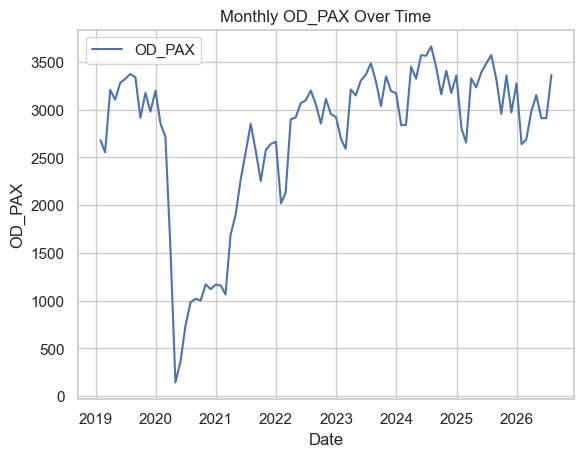

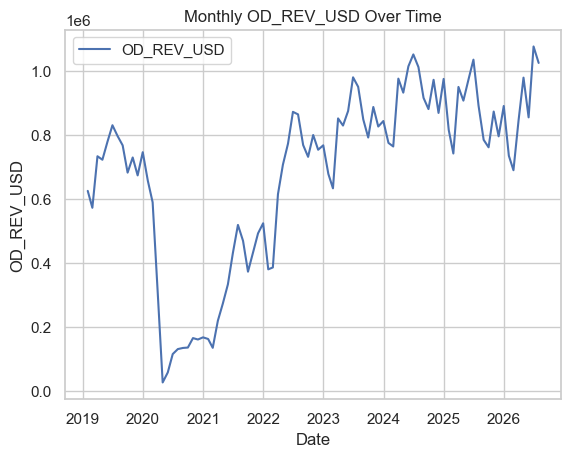

In [39]:

monthly = df.groupby('DATE')[['OD_PAX', 'OD_REV_USD']].mean()
monthly = monthly.resample('ME').mean()



plt.plot(monthly.index, monthly['OD_PAX'], label='OD_PAX')
# plt.axvline(x='2020-03-01', color='red', linestyle='--', label='COVID Shock')
# plt.yscale('log')
plt.xlabel('Date')
plt.ylabel('OD_PAX')
plt.title('Monthly OD_PAX Over Time')
plt.legend()
plt.show()
plt.plot(monthly.index, monthly['OD_REV_USD'], label='OD_REV_USD')
# plt.yscale('log')
plt.xlabel('Date')
plt.ylabel('OD_REV_USD')
plt.title('Monthly OD_REV_USD Over Time')
plt.legend()
plt.show()

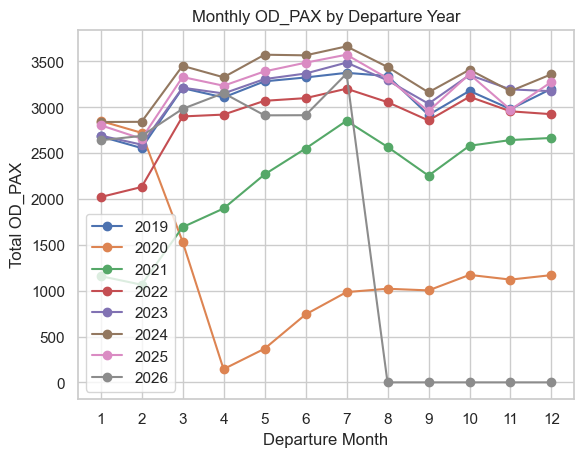

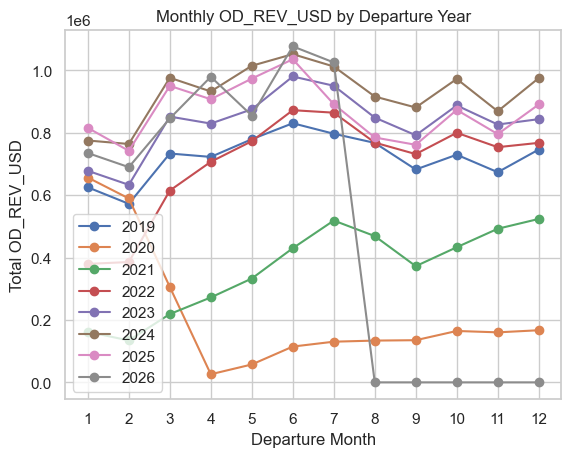

In [40]:

seasonality = df.pivot_table(
    index='DEP_MONTH',
    columns='DEP_YEAR',
    values='OD_PAX',
    aggfunc='mean',
    fill_value=0,
)

plt.plot(seasonality.index, seasonality, marker='o',label=seasonality.columns)
plt.xlabel('Departure Month')
plt.ylabel('Total OD_PAX')
plt.title('Monthly OD_PAX by Departure Year')
plt.xticks(seasonality.index)
plt.legend()
plt.show()

seasonality = df.pivot_table(
    index='DEP_MONTH',
    columns='DEP_YEAR',
    values='OD_REV_USD',
    aggfunc='mean',
    fill_value=0,
)

plt.plot(seasonality.index, seasonality, marker='o',label=seasonality.columns)
plt.xlabel('Departure Month')
plt.ylabel('Total OD_REV_USD')
plt.title('Monthly OD_REV_USD by Departure Year')
plt.xticks(seasonality.index)
plt.legend()
plt.show()


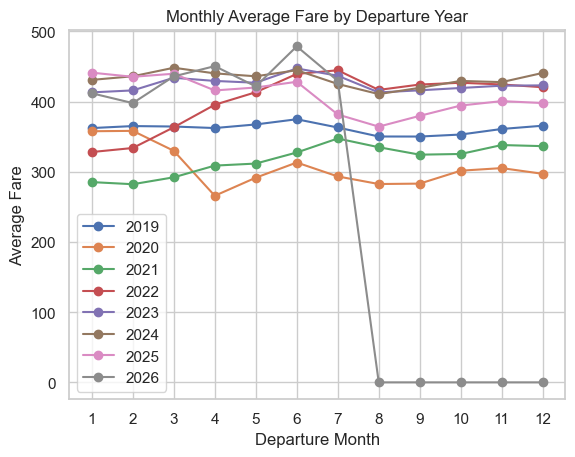

count    91.000000
mean    383.360877
std      52.927735
min     265.874599
25%     342.848265
50%     398.043658
75%     427.410136
max     478.787361
Name: AVG_FARE, dtype: float64
GROUPED BY MONTH
DEP_MONTH
1    379.341020
2    378.920460
3    389.025219
4    386.967207
5    389.233903
6    409.363755
7    391.901062
8    369.141917
9    372.530415
10   379.438447
11   383.379691
12   383.563620
Name: AVG_FARE, dtype: float64


In [41]:

seasonality = df.pivot_table(
    index='DEP_MONTH',
    columns='DEP_YEAR',
    values='AVG_FARE',
    aggfunc='mean',
    fill_value=0,
)

plt.plot(seasonality.index, seasonality, marker='o',label=seasonality.columns)
plt.xlabel('Departure Month')
plt.ylabel('Average Fare')
plt.title('Monthly Average Fare by Departure Year')
plt.xticks(seasonality.index)
plt.legend()
plt.show()
print(df.groupby('DATE')['AVG_FARE'].mean().describe())
print("GROUPED BY MONTH")
print(df.groupby("DEP_MONTH")["AVG_FARE"].mean())

I expected to find price and passenger spikes during summer break, but there were none/the difference was very unnoticeable.

---
# 7 Correlations

In [43]:
df.head()

,DEP_MONTH,DEP_YEAR,DATE,ORG_AIRPRT,DES_AIRPRT,ROUTE,OD_PAX,OD_REV_USD,AVG_FARE,AVG_FARE_LOG,OD_REV_USD_LOG,OD_PAX_LOG,ORG_AIRPRT_CD,ORG_AIRPRT_NM,ORG_CITY_METRO_IATA_CD,ORG_STATE_PROVNC_CD,ORG_CNTRY_CD,ORG_WRLD_AREA_DOT_CD,ORG_LNGST_RUNWAY_FT_QTY,ORG_ELEVATN_FT_QTY,ORG_LAT,ORG_LNGTD,DES_AIRPRT_CD,DES_AIRPRT_NM,DES_CITY_METRO_IATA_CD,DES_STATE_PROVNC_CD,DES_CNTRY_CD,DES_WRLD_AREA_DOT_CD,DES_LNGST_RUNWAY_FT_QTY,DES_ELEVATN_FT_QTY,DES_LAT,DES_LNGTD
0,12,2023,2023-12-01,SAN,PVR,SAN-PVR,"3,609.91","562,691.27",155.87,5.06,13.24,8.19,SAN,San Diego Intl.,SAN,CA,US,91,9400,17,32.73,-117.19,PVR,G.Diaz Ordaz Intl,PVR,MISSING,MX,148,10100,23,20.68,-105.25
1,12,2019,2019-12-01,SAN,PVR,SAN-PVR,"3,271.89","533,964.07",163.20,5.10,13.19,8.09,SAN,San Diego Intl.,SAN,CA,US,91,9400,17,32.73,-117.19,PVR,G.Diaz Ordaz Intl,PVR,MISSING,MX,148,10100,23,20.68,-105.25
2,8,2022,2022-08-01,SAN,PVR,SAN-PVR,"1,435.84","167,189.61",116.44,4.77,12.03,7.27,SAN,San Diego Intl.,SAN,CA,US,91,9400,17,32.73,-117.19,PVR,G.Diaz Ordaz Intl,PVR,MISSING,MX,148,10100,23,20.68,-105.25
3,2,2021,2021-02-01,SAN,PVR,SAN-PVR,546.57,"80,287.17",146.89,5.00,11.29,6.31,SAN,San Diego Intl.,SAN,CA,US,91,9400,17,32.73,-117.19,PVR,G.Diaz Ordaz Intl,PVR,MISSING,MX,148,10100,23,20.68,-105.25
4,5,2021,2021-05-01,SAN,PVR,SAN-PVR,"1,741.58","273,545.15",157.07,5.06,12.52,7.46,SAN,San Diego Intl.,SAN,CA,US,91,9400,17,32.73,-117.19,PVR,G.Diaz Ordaz Intl,PVR,MISSING,MX,148,10100,23,20.68,-105.25


In [ ]:
df_copy = df.copy()
# df.drop(columns=['DATE','OD_PAX','OD_REV_USD','AVG_FARE','ORG_AIRPRT_NM','ORG_CITY_METRO_IATA_CD','ORG_WRLD_AREA_DOT_CD',
#                  'ORG_AIRPRT_CD','DES_AIRPRT_CD','DES_AIRPRT_NM','DES_CITY_METRO_IATA_CD','DES_WRLD_AREA_DOT_CD',
                #  'AVG_FARE_LOG'],inplace=True)


df.head()

,DEP_MONTH,DEP_YEAR,ORG_AIRPRT,DES_AIRPRT,ROUTE,OD_REV_USD_LOG,OD_PAX_LOG,ORG_STATE_PROVNC_CD,ORG_CNTRY_CD,ORG_LNGST_RUNWAY_FT_QTY,ORG_ELEVATN_FT_QTY,ORG_LAT,ORG_LNGTD,DES_STATE_PROVNC_CD,DES_CNTRY_CD,DES_LNGST_RUNWAY_FT_QTY,DES_ELEVATN_FT_QTY,DES_LAT,DES_LNGTD
0,12,2023,SAN,PVR,SAN-PVR,13.24,8.19,CA,US,9400,17,32.73,-117.19,MISSING,MX,10100,23,20.68,-105.25
1,12,2019,SAN,PVR,SAN-PVR,13.19,8.09,CA,US,9400,17,32.73,-117.19,MISSING,MX,10100,23,20.68,-105.25
2,8,2022,SAN,PVR,SAN-PVR,12.03,7.27,CA,US,9400,17,32.73,-117.19,MISSING,MX,10100,23,20.68,-105.25
3,2,2021,SAN,PVR,SAN-PVR,11.29,6.31,CA,US,9400,17,32.73,-117.19,MISSING,MX,10100,23,20.68,-105.25
4,5,2021,SAN,PVR,SAN-PVR,12.52,7.46,CA,US,9400,17,32.73,-117.19,MISSING,MX,10100,23,20.68,-105.25


In [75]:
#preparing to encode categorical variables
y = df[['OD_PAX_LOG','OD_REV_USD_LOG']]
X = df.drop(columns=['OD_PAX_LOG','OD_REV_USD_LOG'])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

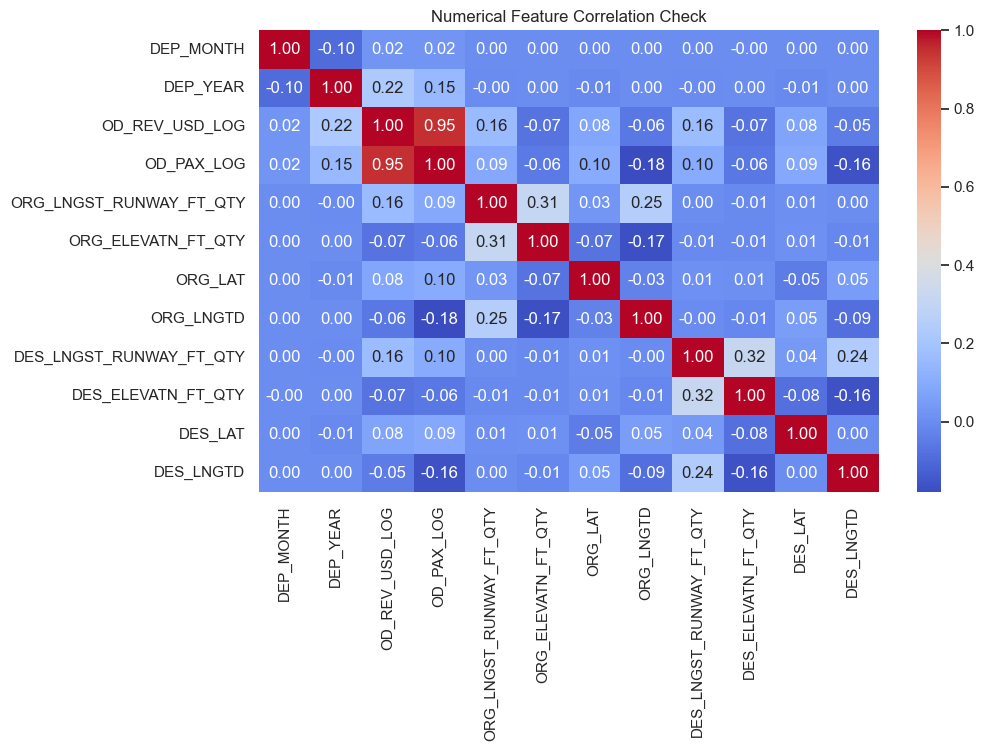

In [76]:

numeric_cols = [
    'DEP_MONTH', 'DEP_YEAR', 'OD_REV_USD_LOG',
    'OD_PAX_LOG', 'ORG_LNGST_RUNWAY_FT_QTY', 'ORG_ELEVATN_FT_QTY', 'ORG_LAT',
    'ORG_LNGTD', 'DES_LNGST_RUNWAY_FT_QTY', 'DES_ELEVATN_FT_QTY', 'DES_LAT',
    'DES_LNGTD'
]

plt.figure(figsize=(10,6))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Numerical Feature Correlation Check")
plt.show()

---
# 8. Build Model

In [77]:
import time

In [78]:


def build_and_evaluate_flight_model(X_train, X_test, y_train, y_test, target_name):
    """
    Builds, cross-validates, and trains a pipeline for a log-transformed target.
    Automatically applies inverse-log transformation for real-world metrics.
    """
    print(f"\n=====================================================================")
    print(f"🚀 INITIALIZING LOG-AWARE TRAINING PIPELINE FOR: {target_name.upper()}")
    print(f"=====================================================================")
    
    # 1. SETUP MASTER REPRODUCIBLE STRING DICTIONARIES
    master_states = sorted(list(
        set(X_train['ORG_STATE_PROVNC_CD']).union(set(X_train['DES_STATE_PROVNC_CD']))
        .union(set(X_test['ORG_STATE_PROVNC_CD'])).union(set(X_test['DES_STATE_PROVNC_CD']))
    ))
    master_countries = sorted(list(
        set(X_train['ORG_CNTRY_CD']).union(set(X_train['DES_CNTRY_CD']))
        .union(set(X_test['ORG_CNTRY_CD'])).union(set(X_test['DES_CNTRY_CD']))
    ))
    master_airports = sorted(list(
        set(X_train['ORG_AIRPRT']).union(set(X_train['DES_AIRPRT']))
        .union(set(X_test['ORG_AIRPRT'])).union(set(X_test['DES_AIRPRT']))
    ))

    # 2. INITIALIZE ISOLATED OBJECT INSTANCES
    fresh_route_encoder = TargetEncoder(smooth='auto', cv=5, random_state=42)
    state_encoder = OrdinalEncoder(categories=[master_states, master_states], handle_unknown='use_encoded_value', unknown_value=-1)
    country_encoder = OrdinalEncoder(categories=[master_countries, master_countries], handle_unknown='use_encoded_value', unknown_value=-1)
    airport_encoder = OrdinalEncoder(categories=[master_airports, master_airports], handle_unknown='use_encoded_value', unknown_value=-1)
    
    preprocessor = ColumnTransformer(
        transformers=[
            ('route_target', fresh_route_encoder, ['ROUTE']),
            ('states_ordinal', state_encoder, ['ORG_STATE_PROVNC_CD', 'DES_STATE_PROVNC_CD']),
            ('countries_ordinal', country_encoder, ['ORG_CNTRY_CD', 'DES_CNTRY_CD']),
            ('airports_ordinal', airport_encoder, ['ORG_AIRPRT', 'DES_AIRPRT'])
        ],
        remainder='passthrough'
    )
    
    fresh_rf = RandomForestRegressor(
        n_estimators=30, max_depth=12, min_samples_split=50, n_jobs=8, random_state=42
    )

    pipeline = Pipeline(steps=[
        ('preprocessing', preprocessor),
        ('model', fresh_rf)
    ])

    # 3. RUN K-FOLD CROSS-VALIDATION (Evaluates log-scale baseline)
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    print(f"⏳ Running 5-Fold Cross-Validation on training pool...")
    cv_start = time.time()
    cv_scores = cross_val_score(pipeline, X_train, y_train[target_name], cv=kf, scoring='r2', n_jobs=1)
    cv_end = time.time()
    print(f"📊 K-Fold Log-Scale R² Scores: {np.round(cv_scores, 4)}")
    print(f"🏆 Mean K-Fold Log-Scale R²: {np.mean(cv_scores):.4f} (Took {(cv_end - cv_start) / 60:.2f} mins)")

    # 4. FINAL FIT 
    print(f"🎓 Training final model on entire training matrix...")
    pipeline.fit(X_train, y_train[target_name])
    
    # 5. INVERSE-LOG TEST EVALUATION (REAL WORLD UNITS)
    # Generate predictions (which will come out as logged numbers)
    y_pred_log = pipeline.predict(X_test)
    
    # Reverse the log transform to get back to dollars/minutes
    # (Using expm1 assuming targets were logged using log1p)
    y_true_real = np.expm1(y_test[target_name])
    y_pred_real = np.expm1(y_pred_log)
    
    # Calculate true, honest metrics on the real-world scale!
    real_world_mae = mean_absolute_error(y_true_real, y_pred_real)
    real_world_r2 = r2_score(y_true_real, y_pred_real)
    
    print(f"\n🎯 --- FINAL REAL-WORLD HOLDOUT METRICS ---")
    print(f"💵 Real-World Mean Absolute Error (MAE): {real_world_mae:.2f} (in original units)")
    print(f"📈 Real-World Final R² Score: {real_world_r2:.4f}")
    
    return pipeline


In [80]:
model_predictions = {}
model_predictions['OD_REV_USD_PRED'] = build_and_evaluate_flight_model(X_train, X_test, y_train, y_test, 'OD_REV_USD_LOG')
model_predictions['OD_PAX_PRED'] = build_and_evaluate_flight_model(X_train, X_test, y_train, y_test, 'OD_PAX_LOG')



🚀 INITIALIZING LOG-AWARE TRAINING PIPELINE FOR: OD_REV_USD_LOG
⏳ Running 5-Fold Cross-Validation on training pool...
📊 K-Fold Log-Scale R² Scores: [0.9077 0.9083 0.9081 0.9061 0.9075]
🏆 Mean K-Fold Log-Scale R²: 0.9075 (Took 1.79 mins)
🎓 Training final model on entire training matrix...

🎯 --- FINAL REAL-WORLD HOLDOUT METRICS ---
💵 Real-World Mean Absolute Error (MAE): 167104.08 (in original units)
📈 Real-World Final R² Score: 0.9202

🚀 INITIALIZING LOG-AWARE TRAINING PIPELINE FOR: OD_PAX_LOG
⏳ Running 5-Fold Cross-Validation on training pool...
📊 K-Fold Log-Scale R² Scores: [0.9294 0.9307 0.9301 0.9292 0.9304]
🏆 Mean K-Fold Log-Scale R²: 0.9300 (Took 1.76 mins)
🎓 Training final model on entire training matrix...

🎯 --- FINAL REAL-WORLD HOLDOUT METRICS ---
💵 Real-World Mean Absolute Error (MAE): 569.95 (in original units)
📈 Real-World Final R² Score: 0.9500


In [82]:
# pred = pd.DataFrame(model_predictions)
# pred.head()
model_predictions

{'OD_REV_USD_PRED': Pipeline(steps=[('preprocessing',
                  ColumnTransformer(remainder='passthrough',
                                    transformers=[('route_target',
                                                   TargetEncoder(random_state=42),
                                                   ['ROUTE']),
                                                  ('states_ordinal',
                                                   OrdinalEncoder(categories=[['AB',
                                                                               'AK',
                                                                               'AL',
                                                                               'AR',
                                                                               'AZ',
                                                                               'BA',
                                                                               'BC',
        

---
# 9 Summary 



### Methods
1. Loaded the dataset and inspected
2. Filled in missing values and dropped useless columns
3. Created a function that first:
4. Builds a pipeline for encoding categorical variables
5. Evaluates using KFold Validation
6. Train again on train set
7. Tests on test set and evaluates
